In [1]:
import numpy as np
import pandas as pd

In [2]:
#load datasets
df=pd.read_csv("india_housing_prices.csv")
print(df)

            ID        State       City      Locality      Property_Type  BHK  \
0            1   Tamil Nadu    Chennai   Locality_84          Apartment    1   
1            2  Maharashtra       Pune  Locality_490  Independent House    3   
2            3       Punjab   Ludhiana  Locality_167          Apartment    2   
3            4    Rajasthan    Jodhpur  Locality_393  Independent House    2   
4            5    Rajasthan     Jaipur  Locality_466              Villa    4   
...        ...          ...        ...           ...                ...  ...   
249995  249996      Gujarat  Ahmedabad  Locality_187  Independent House    5   
249996  249997   Tamil Nadu    Chennai  Locality_348          Apartment    1   
249997  249998    Telangana   Warangal  Locality_225              Villa    4   
249998  249999       Odisha    Cuttack  Locality_138              Villa    1   
249999  250000      Haryana    Gurgaon  Locality_268  Independent House    3   

        Size_in_SqFt  Price_in_Lakhs  P

In [3]:
#preprocessing
df.shape

(250000, 23)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  object 
 2   City                            250000 non-null  object 
 3   Locality                        250000 non-null  object 
 4   Property_Type                   250000 non-null  object 
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  object 
 11  Floor_No                        250000 non-null  int64  
 12  Total_Floors    

In [5]:
#find & handle the  missingvalues
df.isnull()

,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
249996,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
249997,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
249998,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [6]:
df.isnull().sum()

ID                                0
State                             0
City                              0
Locality                          0
Property_Type                     0
BHK                               0
Size_in_SqFt                      0
Price_in_Lakhs                    0
Price_per_SqFt                    0
Year_Built                        0
Furnished_Status                  0
Floor_No                          0
Total_Floors                      0
Age_of_Property                   0
Nearby_Schools                    0
Nearby_Hospitals                  0
Public_Transport_Accessibility    0
Parking_Space                     0
Security                          0
Amenities                         0
Facing                            0
Owner_Type                        0
Availability_Status               0
dtype: int64

In [7]:
#duplicate value
df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
249995    False
249996    False
249997    False
249998    False
249999    False
Length: 250000, dtype: bool

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
#datatypes
df.dtypes

ID                                  int64
State                              object
City                               object
Locality                           object
Property_Type                      object
BHK                                 int64
Size_in_SqFt                        int64
Price_in_Lakhs                    float64
Price_per_SqFt                    float64
Year_Built                          int64
Furnished_Status                   object
Floor_No                            int64
Total_Floors                        int64
Age_of_Property                     int64
Nearby_Schools                      int64
Nearby_Hospitals                    int64
Public_Transport_Accessibility     object
Parking_Space                      object
Security                           object
Amenities                          object
Facing                             object
Owner_Type                         object
Availability_Status                object
dtype: object

In [10]:
#statistical summary
df.describe()

,ID,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals
count,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000
mean,125000.500000,2.999396,2749.813216,254.586854,0.130597,2006.520012,14.966800,15.503004,18.479988,5.499860,5.498016
std,72168.927986,1.415521,1300.606954,141.349921,0.130747,9.808575,8.948047,8.671618,9.808575,2.878639,2.871860
min,1.000000,1.000000,500.000000,10.000000,0.000000,1990.000000,0.000000,1.000000,2.000000,1.000000,1.000000
25%,62500.750000,2.000000,1623.000000,132.550000,0.050000,1998.000000,7.000000,8.000000,10.000000,3.000000,3.000000
50%,125000.500000,3.000000,2747.000000,253.870000,0.090000,2007.000000,15.000000,15.000000,18.000000,5.000000,5.000000
75%,187500.250000,4.000000,3874.000000,376.880000,0.160000,2015.000000,23.000000,23.000000,27.000000,8.000000,8.000000
max,250000.000000,5.000000,5000.000000,500.000000,0.990000,2023.000000,30.000000,30.000000,35.000000,10.000000,10.000000


In [11]:
#convert text column locality into numbers

df['Locality_Encoded'] = df['Locality'].astype('category').cat.codes
print(df)


            ID        State       City      Locality      Property_Type  BHK  \
0            1   Tamil Nadu    Chennai   Locality_84          Apartment    1   
1            2  Maharashtra       Pune  Locality_490  Independent House    3   
2            3       Punjab   Ludhiana  Locality_167          Apartment    2   
3            4    Rajasthan    Jodhpur  Locality_393  Independent House    2   
4            5    Rajasthan     Jaipur  Locality_466              Villa    4   
...        ...          ...        ...           ...                ...  ...   
249995  249996      Gujarat  Ahmedabad  Locality_187  Independent House    5   
249996  249997   Tamil Nadu    Chennai  Locality_348          Apartment    1   
249997  249998    Telangana   Warangal  Locality_225              Villa    4   
249998  249999       Odisha    Cuttack  Locality_138              Villa    1   
249999  250000      Haryana    Gurgaon  Locality_268  Independent House    3   

        Size_in_SqFt  Price_in_Lakhs  P

In [12]:
#Feature engineering(new column creating)
#Creat Amenities count column

df['Amenities_Count']= df['Amenities'].str.count(',')+1


In [13]:
#creating floor Ratio (dividing floor_no by total_floors)
df['Floor_Ratio']=df['Floor_No']/df['Total_Floors'].replace(0,1)#here use replace(0,1) to handle division by zero if total_floors  is   '0'


In [14]:
#creating total_infrastructure score( combining nearby_school + neraby_hospitals)
df['Total_Infrastructure_score']=df['Nearby_Schools']+df['Nearby_Hospitals']


In [15]:
#Create Good Investment
df['Good_Investment']=df['Price_per_SqFt']<=(df.groupby('City')['Price_per_SqFt'].transform('median'))


In [16]:
df['Good_Investment']=df['Good_Investment'].astype(int)
print(df)

            ID        State       City      Locality      Property_Type  BHK  \
0            1   Tamil Nadu    Chennai   Locality_84          Apartment    1   
1            2  Maharashtra       Pune  Locality_490  Independent House    3   
2            3       Punjab   Ludhiana  Locality_167          Apartment    2   
3            4    Rajasthan    Jodhpur  Locality_393  Independent House    2   
4            5    Rajasthan     Jaipur  Locality_466              Villa    4   
...        ...          ...        ...           ...                ...  ...   
249995  249996      Gujarat  Ahmedabad  Locality_187  Independent House    5   
249996  249997   Tamil Nadu    Chennai  Locality_348          Apartment    1   
249997  249998    Telangana   Warangal  Locality_225              Villa    4   
249998  249999       Odisha    Cuttack  Locality_138              Villa    1   
249999  250000      Haryana    Gurgaon  Locality_268  Independent House    3   

        Size_in_SqFt  Price_in_Lakhs  P

In [17]:
#check index no for each  column
list(enumerate(df.columns))

[(0, 'ID'),
 (1, 'State'),
 (2, 'City'),
 (3, 'Locality'),
 (4, 'Property_Type'),
 (5, 'BHK'),
 (6, 'Size_in_SqFt'),
 (7, 'Price_in_Lakhs'),
 (8, 'Price_per_SqFt'),
 (9, 'Year_Built'),
 (10, 'Furnished_Status'),
 (11, 'Floor_No'),
 (12, 'Total_Floors'),
 (13, 'Age_of_Property'),
 (14, 'Nearby_Schools'),
 (15, 'Nearby_Hospitals'),
 (16, 'Public_Transport_Accessibility'),
 (17, 'Parking_Space'),
 (18, 'Security'),
 (19, 'Amenities'),
 (20, 'Facing'),
 (21, 'Owner_Type'),
 (22, 'Availability_Status'),
 (23, 'Locality_Encoded'),
 (24, 'Amenities_Count'),
 (25, 'Floor_Ratio'),
 (26, 'Total_Infrastructure_score'),
 (27, 'Good_Investment')]

In [18]:
# Feature selection & labeling independet variales &dependent variables
X = df.drop(columns=['ID','Good_Investment','Furnished_Status','Public_Transport_Accessibility','Parking_Space','Security','Amenities','Facing','Owner_Type','Availability_Status','State','City','Locality','Property_Type']).values
# y gets only the target column
y = df['Good_Investment'].values

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [20]:
# 2. Split into Training and Testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [21]:
# 3. Apply Feature Scaling to X 
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [22]:
#Creating RandomForestClassifier Classifier
from sklearn.ensemble import RandomForestClassifier
model=RandomForestClassifier()

In [23]:
#Training the model using fit function
model.fit(X_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [24]:
#Predicting the  values
y_pred=model.predict(X_test)
y_pred

array([0, 1, 1, ..., 1, 0, 1], shape=(50000,))

In [25]:
#confusion  matrix
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
cm=confusion_matrix(y_test,y_pred,labels=[0,1])
print("Confusion matrix:\n",cm)

Confusion matrix:
 [[24234     0]
 [   98 25668]]


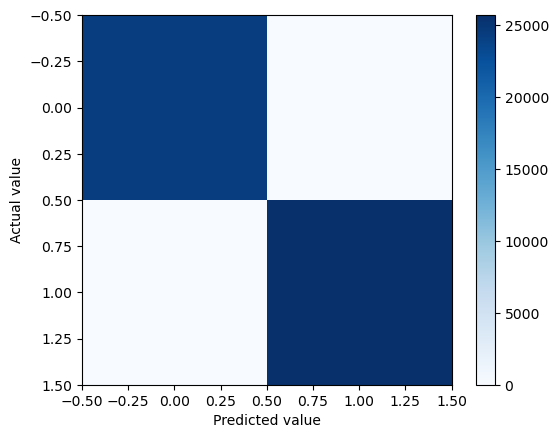

In [26]:
#displaying color bar
import matplotlib.pyplot as plt
plt.imshow(cm,cmap=plt.cm.Blues)
plt.colorbar()
plt.xlabel("Predicted value")
plt.ylabel("Actual value")
plt.show()

<Axes: >

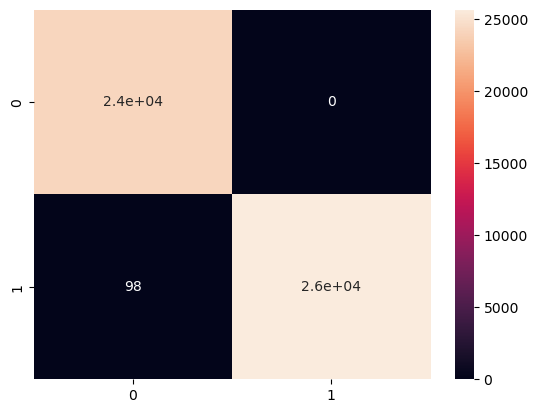

In [27]:
#visualization using Heatmap
import seaborn as sns
sns.heatmap(cm,annot=True)

In [28]:
#Classification report
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     24234
           1       1.00      1.00      1.00     25766

    accuracy                           1.00     50000
   macro avg       1.00      1.00      1.00     50000
weighted avg       1.00      1.00      1.00     50000



##### Distribution of Property Prices

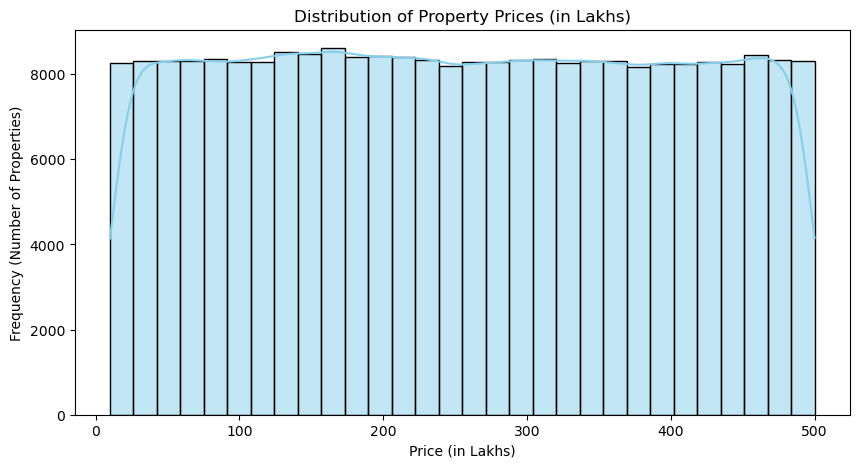

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

# Histogram with a Kernel Density Estimate (KDE) curve
plt.figure(figsize=(10, 5))
sns.histplot(df['Price_in_Lakhs'], kde=True, bins=30, color='skyblue')
plt.title('Distribution of Property Prices (in Lakhs)')
plt.xlabel('Price (in Lakhs)')
plt.ylabel('Frequency (Number of Properties)')
plt.show()

In [30]:
df['Price_in_Lakhs'].describe()

count    250000.000000
mean        254.586854
std         141.349921
min          10.000000
25%         132.550000
50%         253.870000
75%         376.880000
max         500.000000
Name: Price_in_Lakhs, dtype: float64

import plotly.express as px

# Create an interactive histogram
fig = px.histogram(
    df, 
    x='Price_in_Lakhs', 
    nbins=30, 
    title='Interactive Distribution of Property Prices (in Lakhs)',
    labels={'Price_in_Lakhs': 'Price (in Lakhs)'},
    color_discrete_sequence=['skyblue']
)

# Customize layout appearance if needed
fig.update_layout(
    xaxis_title='Price (in Lakhs)',
    yaxis_title='Frequency (Number of Properties)',
    bargap=0.1
)

# Show the interactive chart
fig.show()

## Price & Size Analysis

##### Distribution of size

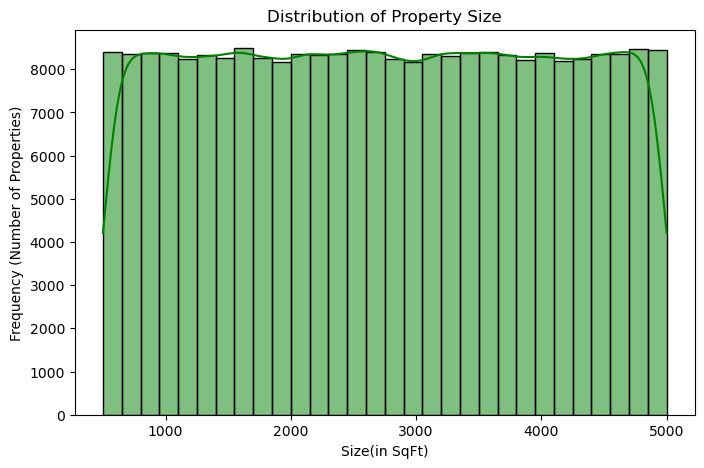

In [31]:

# Histogram with a Kernel Density Estimate (KDE) curve
plt.figure(figsize=(8, 5))
sns.histplot(df['Size_in_SqFt'], kde=True, bins=30, color='Green') 
plt.title('Distribution of Property Size')
plt.xlabel('Size(in SqFt)')
plt.ylabel('Frequency (Number of Properties)')
plt.show()

##### Price_per_SqFt vs Property_Type

C:\Users\DELL\AppData\Local\Temp\ipykernel_54364\4100977936.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Property_Type', y='Price_per_SqFt', palette='Set2')


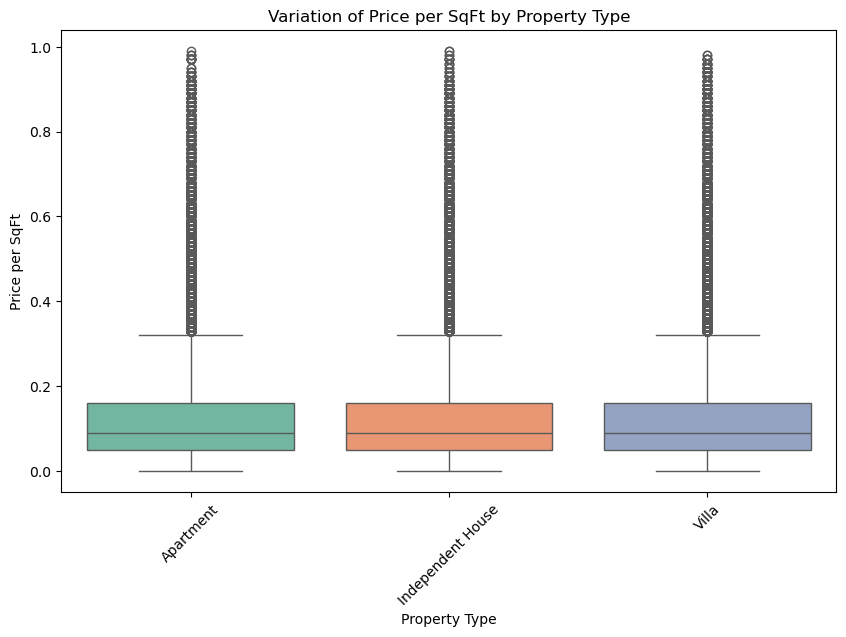

In [32]:
plt.figure(figsize=(10, 6))

# Create a box plot to compare price per sq ft across property types
sns.boxplot(data=df, x='Property_Type', y='Price_per_SqFt', palette='Set2')

plt.title('Variation of Price per SqFt by Property Type')
plt.xlabel('Property Type')
plt.ylabel('Price per SqFt')
plt.xticks(rotation=45) # Rotates labels just in case property type names are long
plt.show()

##### price per sq ft vary by property type

C:\Users\DELL\AppData\Local\Temp\ipykernel_54364\3793333171.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Property_Type', y='Price_per_SqFt', estimator='mean', palette='viridis')


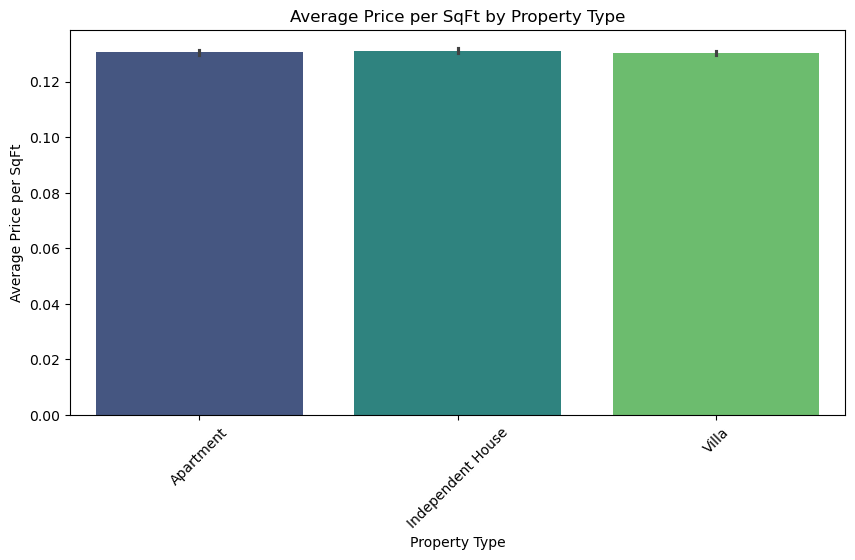

In [33]:
plt.figure(figsize=(10, 5))

# Create a bar plot of average price per sq ft by property type
sns.barplot(data=df, x='Property_Type', y='Price_per_SqFt', estimator='mean', palette='viridis')

plt.title('Average Price per SqFt by Property Type')
plt.xlabel('Property Type')
plt.ylabel('Average Price per SqFt')
plt.xticks(rotation=45)
plt.show()

##### Relation between size & price

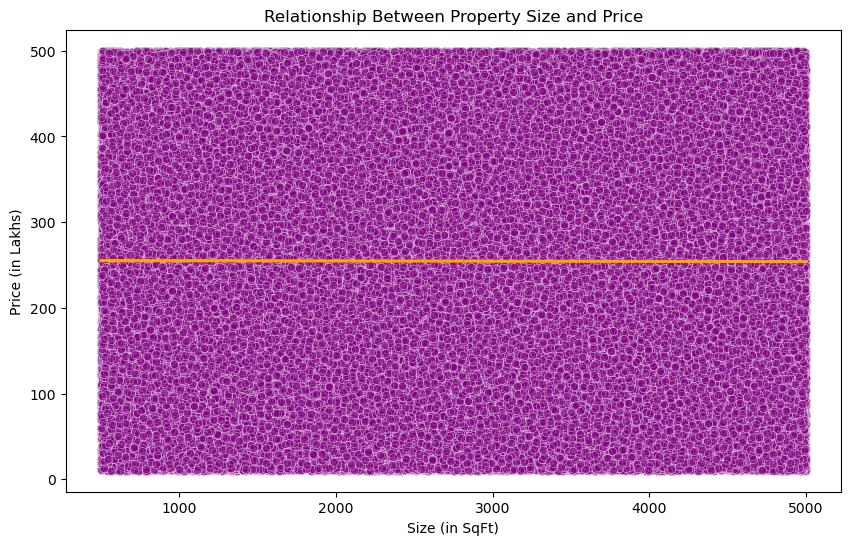

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Create a scatter plot with a regression line
sns.scatterplot(data=df, x='Size_in_SqFt', y='Price_in_Lakhs', alpha=0.5, color='purple')

#  Add a regression trendline to see the direction and strength of the relationship
sns.regplot(data=df, x='Size_in_SqFt', y='Price_in_Lakhs',  scatter=False,  color='orange')

plt.title('Relationship Between Property Size and Price')
plt.xlabel('Size (in SqFt)')
plt.ylabel('Price (in Lakhs)')
plt.show()

#####  outliers in price per sq ft or property size

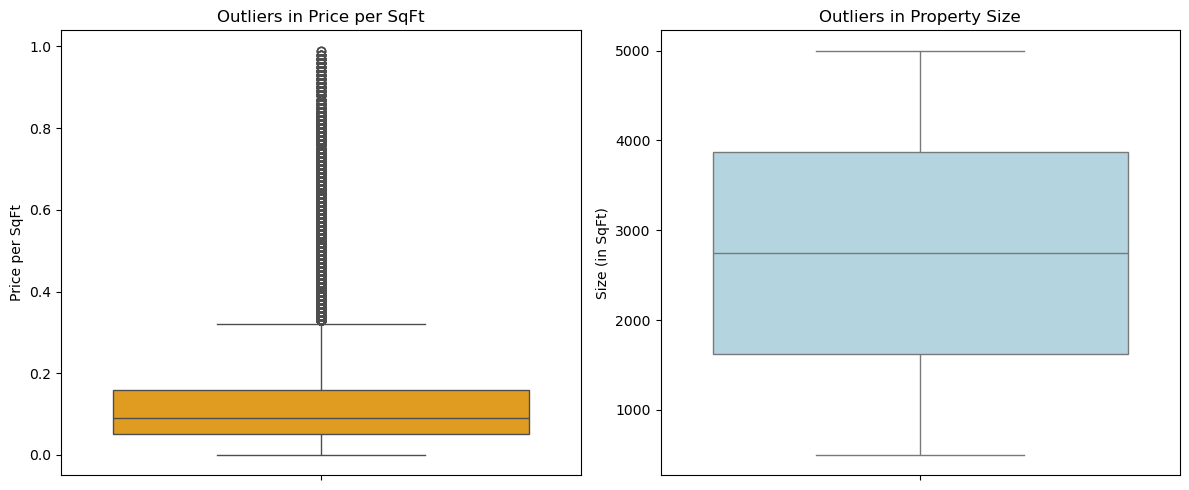

In [36]:
#To check outliers in size & price_per_SqFt
import seaborn as sns
import matplotlib.pyplot as plt

# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Box plot for Price per SqFt
sns.boxplot(ax=axes[0], y=df['Price_per_SqFt'], color='orange')
axes[0].set_title('Outliers in Price per SqFt')
axes[0].set_ylabel('Price per SqFt')

# Box plot for Property Size
sns.boxplot(ax=axes[1], y=df['Size_in_SqFt'], color='lightblue')
axes[1].set_title('Outliers in Property Size')
axes[1].set_ylabel('Size (in SqFt)')

plt.tight_layout()
plt.show()

## Location-based Analysis

#####  average price_per_sqft by state

C:\Users\DELL\AppData\Local\Temp\ipykernel_54364\422907353.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df,x='State',y='Price_per_SqFt',estimator='mean',palette='viridis')


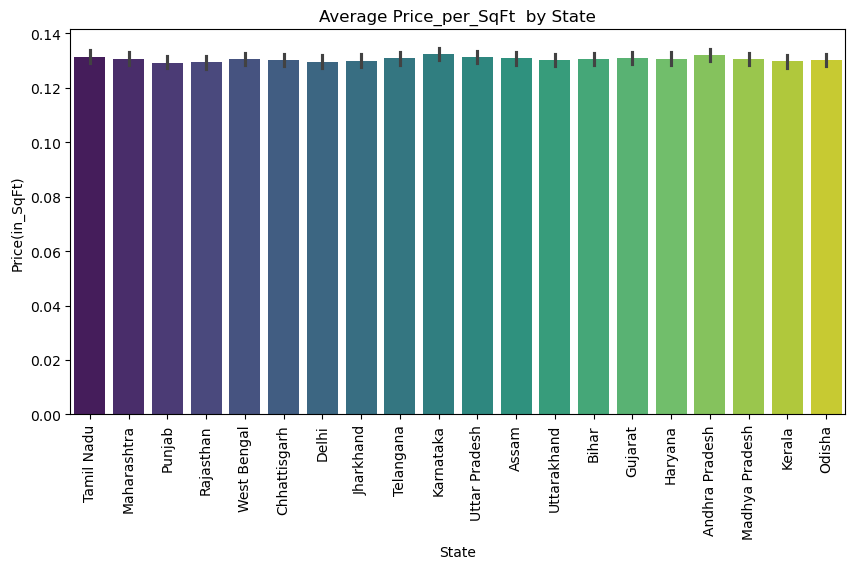

In [37]:
plt.figure(figsize=(10,5))
#create barplot for average of price_per_SqFt by state
sns.barplot(data=df,x='State',y='Price_per_SqFt',estimator='mean',palette='viridis')
plt.title("Average Price_per_SqFt  by State")
plt.xlabel("State")
plt.ylabel("Price(in_SqFt)")
plt.xticks(rotation=90)
plt.show()

##### Average price by city

C:\Users\DELL\AppData\Local\Temp\ipykernel_54364\3353834407.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df,x='City',y='Price_per_SqFt',estimator='mean',palette='viridis')


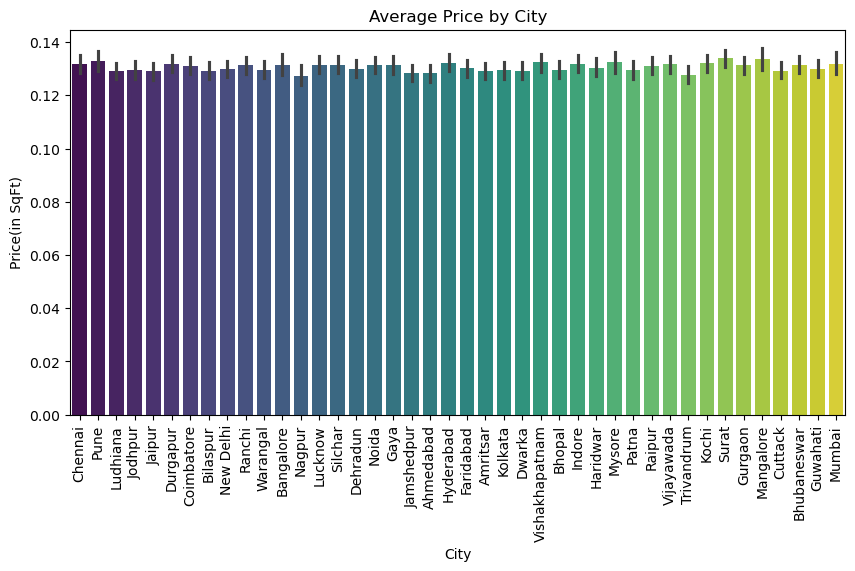

In [38]:
plt.figure(figsize=(10,5))
#create barplot for average price by city
sns.barplot(data=df,x='City',y='Price_per_SqFt',estimator='mean',palette='viridis')
plt.title("Average Price by City")
plt.xlabel("City")
plt.ylabel("Price(in SqFt)")
plt.xticks(rotation=90)
plt.show()

In [39]:
#Encode/convert text to numbers
df['Encode_Property_type']=df['Property_Type'].astype('category').cat.codes

In [40]:
print(df)

            ID        State       City      Locality      Property_Type  BHK  \
0            1   Tamil Nadu    Chennai   Locality_84          Apartment    1   
1            2  Maharashtra       Pune  Locality_490  Independent House    3   
2            3       Punjab   Ludhiana  Locality_167          Apartment    2   
3            4    Rajasthan    Jodhpur  Locality_393  Independent House    2   
4            5    Rajasthan     Jaipur  Locality_466              Villa    4   
...        ...          ...        ...           ...                ...  ...   
249995  249996      Gujarat  Ahmedabad  Locality_187  Independent House    5   
249996  249997   Tamil Nadu    Chennai  Locality_348          Apartment    1   
249997  249998    Telangana   Warangal  Locality_225              Villa    4   
249998  249999       Odisha    Cuttack  Locality_138              Villa    1   
249999  250000      Haryana    Gurgaon  Locality_268  Independent House    3   

        Size_in_SqFt  Price_in_Lakhs  P

##### median age of properties by locality

In [42]:
#calculating median of property age by locality
df['Median_Property_Age']=df.groupby('Locality')['Age_of_Property'].transform('median')

In [43]:
print(df)

            ID        State       City      Locality      Property_Type  BHK  \
0            1   Tamil Nadu    Chennai   Locality_84          Apartment    1   
1            2  Maharashtra       Pune  Locality_490  Independent House    3   
2            3       Punjab   Ludhiana  Locality_167          Apartment    2   
3            4    Rajasthan    Jodhpur  Locality_393  Independent House    2   
4            5    Rajasthan     Jaipur  Locality_466              Villa    4   
...        ...          ...        ...           ...                ...  ...   
249995  249996      Gujarat  Ahmedabad  Locality_187  Independent House    5   
249996  249997   Tamil Nadu    Chennai  Locality_348          Apartment    1   
249997  249998    Telangana   Warangal  Locality_225              Villa    4   
249998  249999       Odisha    Cuttack  Locality_138              Villa    1   
249999  250000      Haryana    Gurgaon  Locality_268  Independent House    3   

        Size_in_SqFt  Price_in_Lakhs  P

C:\Users\DELL\AppData\Local\Temp\ipykernel_54364\1561274032.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plot_df,x='Median_Property_Age',y='Locality',palette='viridis')


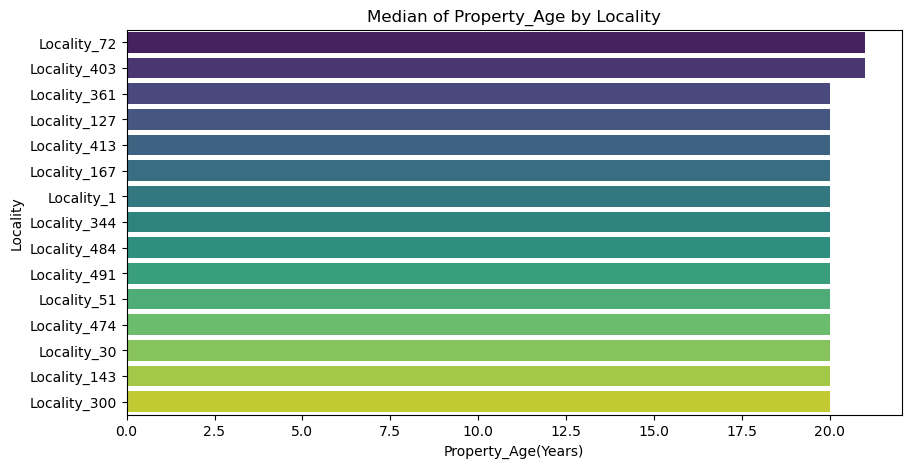

In [44]:
#create barplot for Median of Property_age bylocality
plt.figure(figsize=(10,5))

# 1. Get a unique list of localities and their median ages, then sort and take top 15
plot_df = (df[['Locality', 'Median_Property_Age']].drop_duplicates().sort_values(by='Median_Property_Age', ascending=False).head(15))

sns.barplot(data=plot_df,x='Median_Property_Age',y='Locality',palette='viridis')

plt.title("Median of Property_Age by Locality")
plt.xlabel("Property_Age(Years)")
plt.ylabel("Locality")

plt.show()

#####  BHK distributed across cities

In [45]:
# 1. Create the cross-tabulation table (counts of each BHK type per city)
bhk_city_ct = pd.crosstab(df['City'], df['BHK'])
print('--- Count Table ---')
print(bhk_city_ct)

--- Count Table ---
BHK                1     2     3     4     5
City                                        
Ahmedabad       1264  1267  1272  1258  1350
Amritsar        1284  1239  1234  1224  1240
Bangalore        839   823   802   833   847
Bhopal          1238  1235  1255  1259  1297
Bhubaneswar     1236  1293  1299  1217  1278
Bilaspur        1210  1252  1275  1268  1258
Chennai         1263  1232  1183  1257  1233
Coimbatore      1236  1301  1317  1345  1262
Cuttack         1320  1292  1301  1236  1209
Dehradun        1238  1297  1225  1248  1226
Durgapur        1311  1259  1287  1260  1270
Dwarka          1295  1211  1248  1216  1276
Faridabad       1202  1231  1261  1214  1261
Gaya            1356  1259  1146  1179  1230
Gurgaon         1241  1221  1239  1232  1212
Guwahati        1240  1158  1272  1188  1234
Haridwar        1233  1290  1230  1223  1291
Hyderabad       1190  1312  1256  1271  1244
Indore          1264  1213  1218  1245  1227
Jaipur          1228  1262  1237  1

In [46]:
bhk_city_pct = (
    pd.crosstab(df['City'], df['BHK'], normalize='index') * 100
).round(2)

print('\n--- Percentage Distribution Table (%) ---')
print(bhk_city_pct)


--- Percentage Distribution Table (%) ---
BHK                 1      2      3      4      5
City                                             
Ahmedabad       19.72  19.76  19.84  19.62  21.06
Amritsar        20.64  19.92  19.84  19.68  19.93
Bangalore       20.25  19.86  19.35  20.10  20.44
Bhopal          19.70  19.65  19.97  20.04  20.64
Bhubaneswar     19.55  20.45  20.54  19.25  20.21
Bilaspur        19.32  19.99  20.36  20.25  20.09
Chennai         20.48  19.97  19.18  20.38  19.99
Coimbatore      19.13  20.14  20.38  20.82  19.53
Cuttack         20.76  20.32  20.46  19.44  19.02
Dehradun        19.86  20.81  19.65  20.02  19.67
Durgapur        20.53  19.71  20.15  19.73  19.88
Dwarka          20.73  19.39  19.98  19.47  20.43
Faridabad       19.48  19.95  20.44  19.68  20.44
Gaya            21.98  20.41  18.57  19.11  19.94
Gurgaon         20.20  19.87  20.16  20.05  19.72
Guwahati        20.35  19.01  20.88  19.50  20.26
Haridwar        19.67  20.58  19.63  19.51  20.60
Hyderab

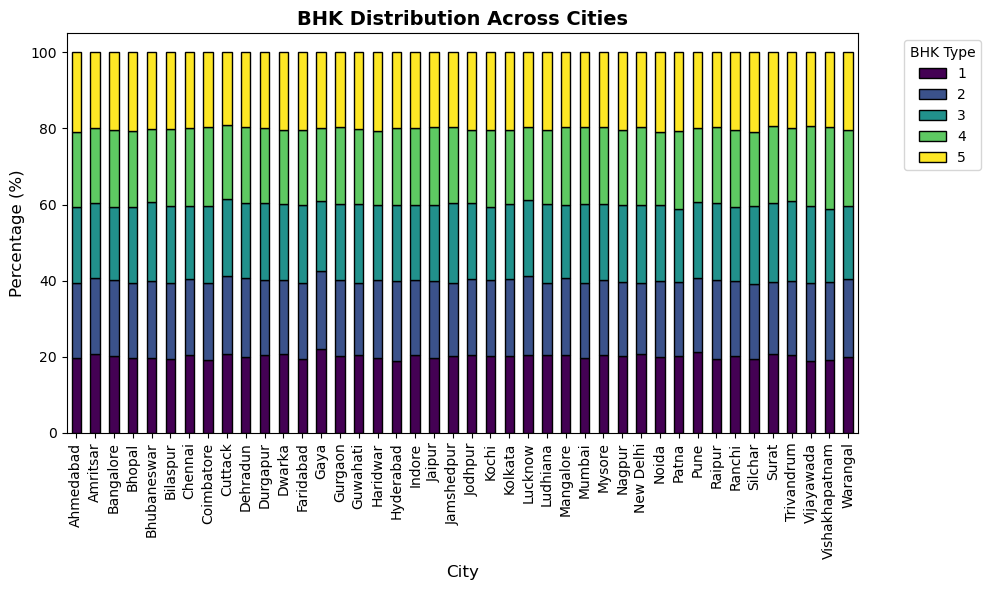

In [47]:
# Plotting the percentage distribution across cities
bhk_city_pct.plot(kind='bar',stacked=True,figsize=(10, 6),colormap='viridis',edgecolor='black',)

plt.title('BHK Distribution Across Cities', fontsize=14, fontweight='bold')
plt.xlabel('City', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.legend(title='BHK Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

#####  price trends for the top 5 most expensive localities

In [48]:
# 1. Identify the top 5 most expensive localities by average/median price
top_5_localities = (df.groupby('Locality')['Price_per_SqFt'].mean().nlargest(5).index.tolist())
print("top 5 localities:",top_5_localities)

top 5 localities: ['Locality_207', 'Locality_416', 'Locality_246', 'Locality_359', 'Locality_387']


In [49]:
# 2. Filter the original dataframe to include only these top 5 localities
top_5_df = df[df['Locality'].isin(top_5_localities)]

In [50]:
price_trends = (top_5_df.groupby('Locality')['Price_per_SqFt'].mean().reset_index())

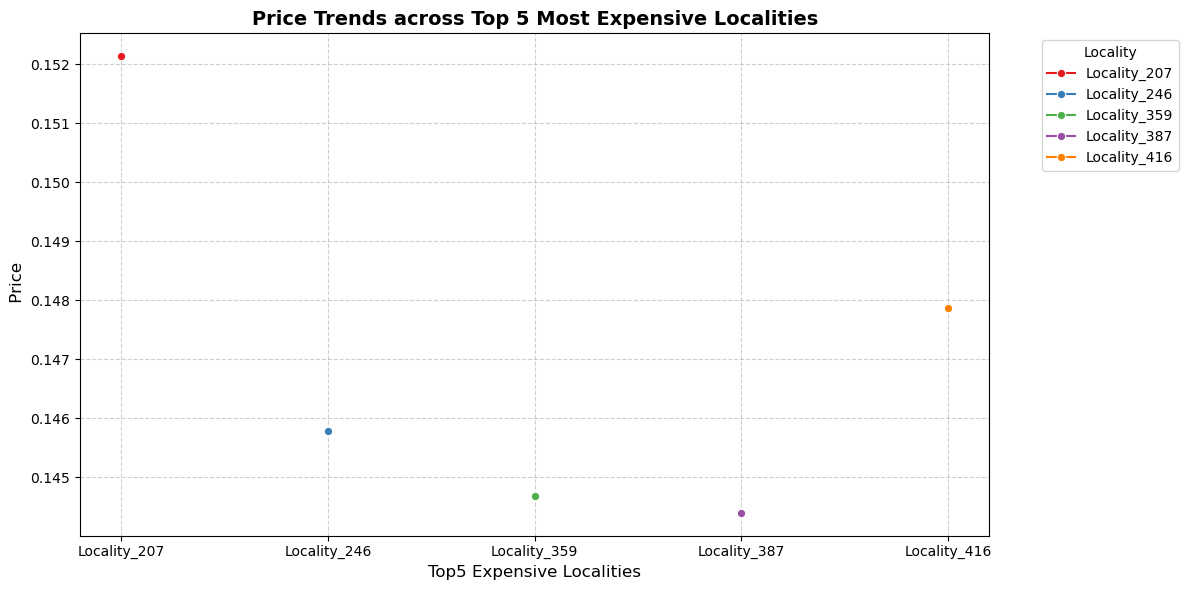

In [51]:
# 4. Plot the price trends using a Line Plot
plt.figure(figsize=(12, 6))
sns.lineplot(data=price_trends,x='Locality',y='Price_per_SqFt',hue='Locality',marker='o',palette='Set1')

plt.title('Price Trends across Top 5 Most Expensive Localities',fontsize=14,fontweight='bold',)
plt.xlabel('Top5 Expensive Localities', fontsize=12)
plt.ylabel(' Price', fontsize=12)
plt.legend(title='Locality', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

##  Feature Relationship & Correlation

##### numeric features correlated with each other

In [52]:
# 1. Select only numeric columns (excluding IDs or non-numeric metadata)
numeric_df = df.select_dtypes(include=['number'])
print(numeric_df)

            ID  BHK  Size_in_SqFt  Price_in_Lakhs  Price_per_SqFt  Year_Built  \
0            1    1          4740          489.76            0.10        1990   
1            2    3          2364          195.52            0.08        2008   
2            3    2          3642          183.79            0.05        1997   
3            4    2          2741          300.29            0.11        1991   
4            5    4          4823          182.90            0.04        2002   
...        ...  ...           ...             ...             ...         ...   
249995  249996    5          1995          274.75            0.14        1995   
249996  249997    1          2293           13.40            0.01        2013   
249997  249998    4          2910          236.94            0.08        2003   
249998  249999    1          1149          141.66            0.12        2007   
249999  250000    3          4313          199.69            0.05        1990   

        Floor_No  Total_Flo

In [53]:
# 2. Compute the correlation matrix 
correlation_matrix = numeric_df.corr()

print('--- Correlation Matrix ---')
print(correlation_matrix)

--- Correlation Matrix ---
                                  ID       BHK  Size_in_SqFt  Price_in_Lakhs  \
ID                          1.000000 -0.001718     -0.002293       -0.001636   
BHK                        -0.001718  1.000000     -0.001033       -0.000980   
Size_in_SqFt               -0.002293 -0.001033      1.000000       -0.002529   
Price_in_Lakhs             -0.001636 -0.000980     -0.002529        1.000000   
Price_per_SqFt             -0.001344  0.001174     -0.614533        0.555625   
Year_Built                  0.002734  0.000917      0.004135        0.002714   
Floor_No                   -0.000214  0.001263     -0.002775       -0.001719   
Total_Floors                0.003382 -0.002862     -0.003451        0.001283   
Age_of_Property            -0.002734 -0.000917     -0.004135       -0.002714   
Nearby_Schools             -0.001203 -0.000762      0.001966        0.000155   
Nearby_Hospitals            0.001429  0.001162     -0.001695       -0.002769   
Locality_Enco

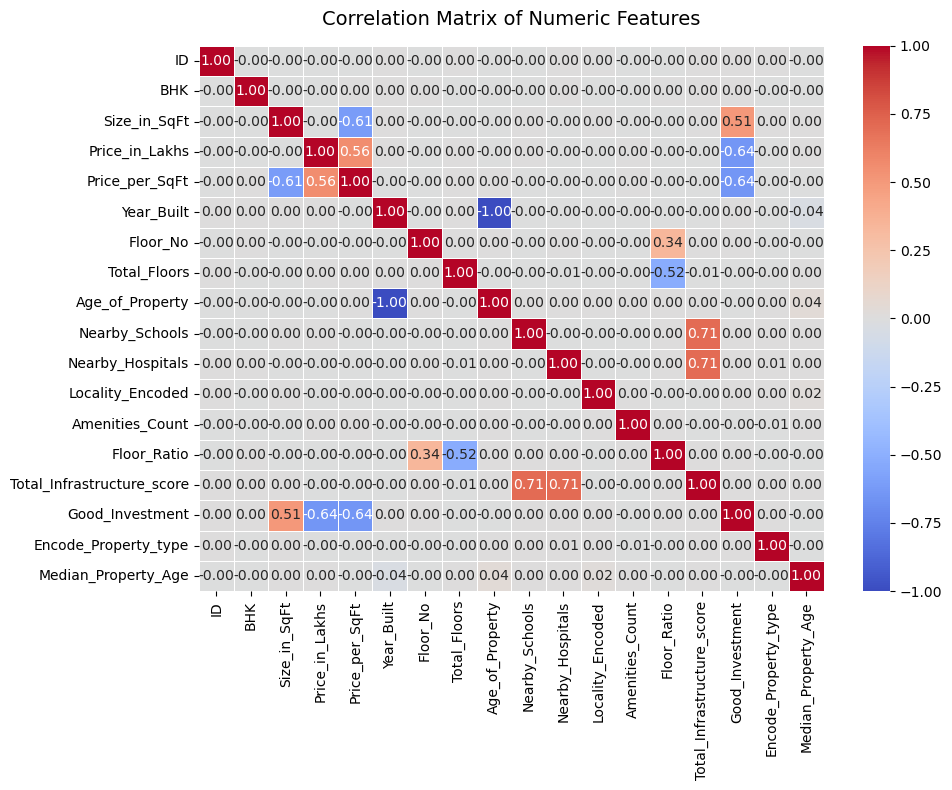

In [54]:
# 3. Visualize the correlation matrix using a Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix,annot=True,fmt='.2f',cmap='coolwarm',linewidths=0.5,vmin=-1,vmax=1,)
plt.title('Correlation Matrix of Numeric Features', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

##### nearby schools relate to price per sq ft

In [55]:
# 1. Check correlation between nearby schools and price per sq ft
correlation = df[['Nearby_Schools', 'Price_per_SqFt']].corr().loc['Nearby_Schools', 'Price_per_SqFt']
print(f'Correlation coefficient: {correlation:.2f}')

Correlation coefficient: -0.00


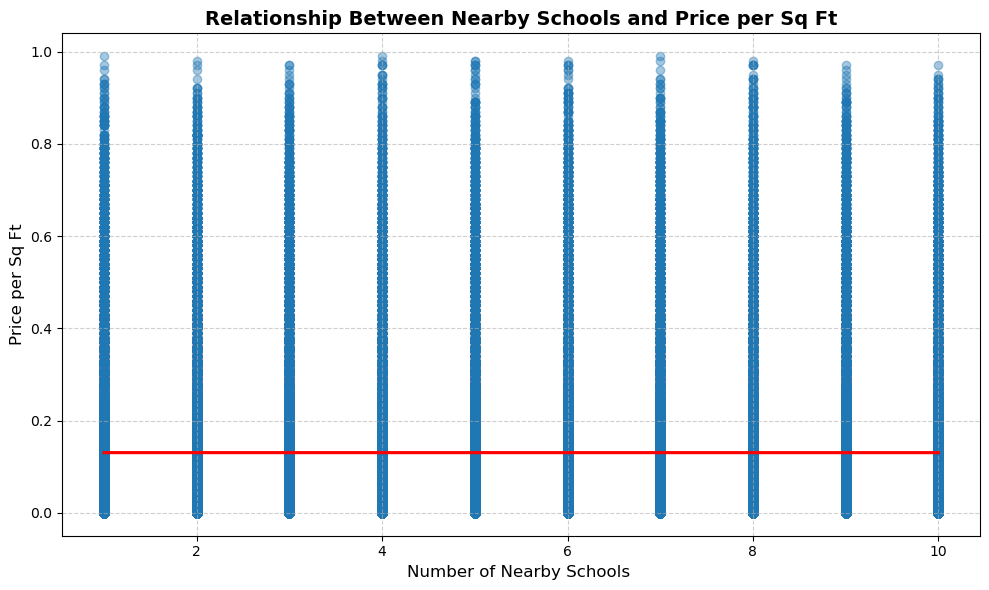

In [56]:
# 2. Visualize the relationship using a Scatter Plot with a Regression Line
plt.figure(figsize=(10, 6))
sns.regplot(data=df,x='Nearby_Schools',y='Price_per_SqFt',scatter_kws={'alpha': 0.4},line_kws={'color': 'red'},)

plt.title('Relationship Between Nearby Schools and Price per Sq Ft',fontsize=14,fontweight='bold')
plt.xlabel('Number of Nearby Schools ', fontsize=12)
plt.ylabel('Price per Sq Ft', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 3. Alternative: Box Plot if 'Nearby_Schools' is categorized or counted discretely
# plt.figure(figsize=(10, 6))
# sns.boxplot(data=df, x='Nearby_Schools', y='Price_per_SqFt', palette='viridis')
# plt.title("Price per Sq Ft Distribution by Number of Nearby Schools")
# plt.show()

#####  nearby hospitals relate to price per sq ft

In [57]:
#corelation between nearby hospitals relate to price per sq ft
cor_relation=df[['Nearby_Hospitals','Price_per_SqFt']].corr().loc['Nearby_Hospitals','Price_per_SqFt']
print(f'Correlation coefficient: {cor_relation:.2f}')


Correlation coefficient: -0.00


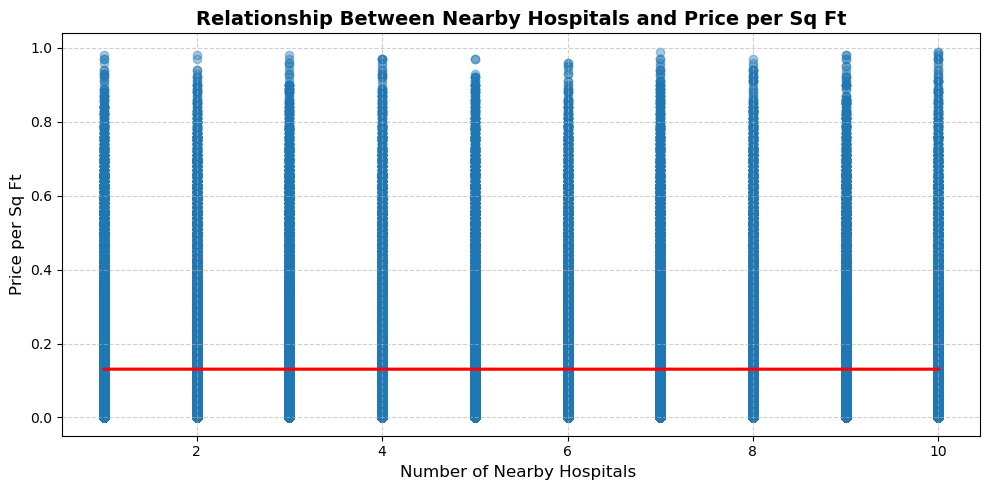

In [58]:
#  Visualize the relationship using a Scatter Plot with a Regression Line
plt.figure(figsize=(10, 5))
sns.regplot(data=df,x='Nearby_Hospitals',y='Price_per_SqFt',scatter_kws={'alpha': 0.4},line_kws={'color': 'red'},)

plt.title('Relationship Between Nearby Hospitals and Price per Sq Ft',fontsize=14,fontweight='bold')
plt.xlabel('Number of Nearby Hospitals ', fontsize=12)
plt.ylabel('Price per Sq Ft', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


#####  price vary by furnished status

In [59]:
# 1. Calculate average and median prices by furnished status
furnished_price = (df.groupby('Furnished_Status')['Price_per_SqFt'] .agg(['mean', 'median', 'count']).reset_index())
print(' Price Summary by Furnished Status ')
print(furnished_price)

 Price Summary by Furnished Status 
  Furnished_Status      mean  median  count
0        Furnished  0.130349    0.09  83218
1   Semi-furnished  0.130947    0.09  83374
2      Unfurnished  0.130493    0.09  83408


C:\Users\DELL\AppData\Local\Temp\ipykernel_54364\3744304020.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,x='Furnished_Status',y='Price_per_SqFt',  palette='Set2')


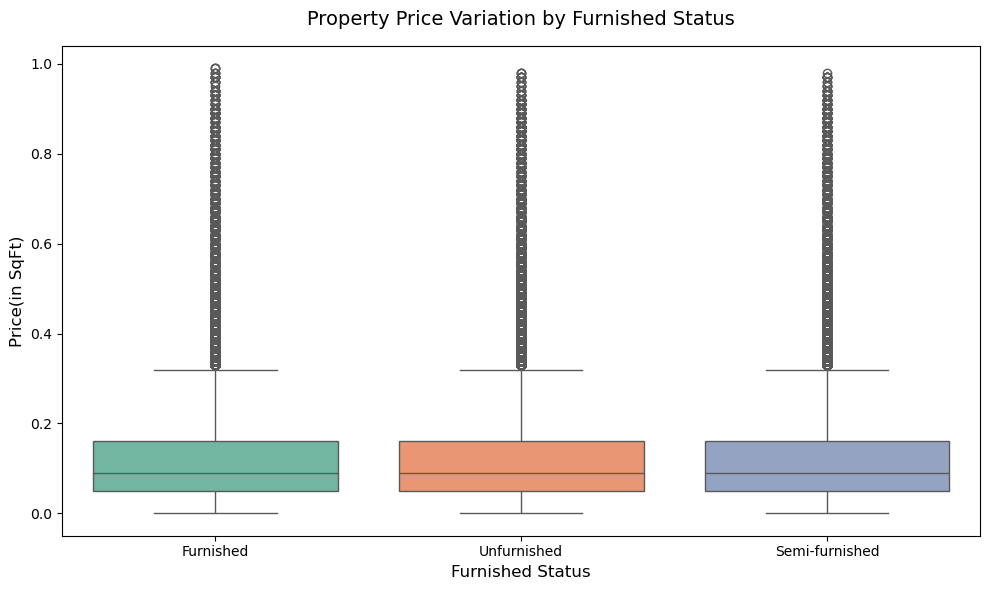

In [60]:
# 2. Visualize the price distribution using a Box Plot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df,x='Furnished_Status',y='Price_per_SqFt',  palette='Set2')
plt.title('Property Price Variation by Furnished Status', fontsize=14, pad=15)
plt.xlabel('Furnished Status', fontsize=12)
plt.ylabel('Price(in SqFt)', fontsize=12)
plt.tight_layout()
plt.show()

#####  price per sq ft vary by property facing direction

In [61]:
#  Calculate average and median prices by furnished status
facing_price = (df.groupby('Facing')['Price_per_SqFt'] .agg(['mean', 'median', 'count']).reset_index().sort_values(by='median',ascending=False))
print(' Price Summary by Facing Directions ')
print(facing_price)

 Price Summary by Facing Directions 
  Facing      mean  median  count
0   East  0.130255    0.09  62269
1  North  0.130252    0.09  62637
2  South  0.130457    0.09  62337
3   West  0.131420    0.09  62757


C:\Users\DELL\AppData\Local\Temp\ipykernel_54364\2671577503.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,x='Facing',y='Price_per_SqFt',  palette='Set2')


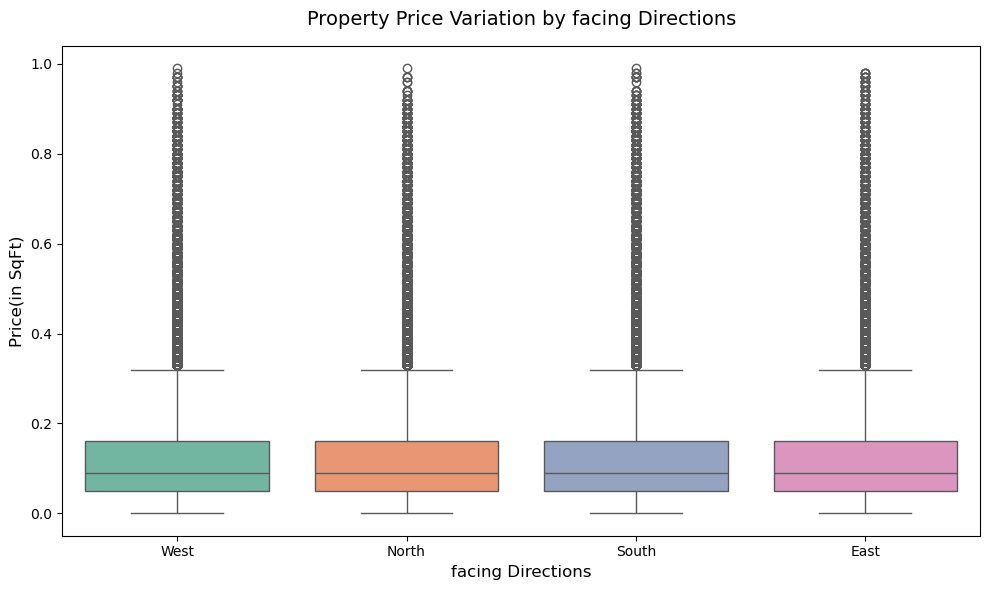

In [62]:
# 2. Visualize the price distribution using a Box Plot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df,x='Facing',y='Price_per_SqFt',  palette='Set2')
plt.title('Property Price Variation by facing Directions', fontsize=14, pad=15)
plt.xlabel('facing Directions', fontsize=12)
plt.ylabel('Price(in SqFt)', fontsize=12)
plt.tight_layout()
plt.show()

## Investment / Amenities / Ownership Analysis 

##### properties belong to each owner type

In [63]:
#  Calculate the count and percentage of properties by Owner Type
owner_counts = df['Owner_Type'].value_counts().reset_index()
owner_counts.columns = ['Owner_Type', 'Count']

owner_counts['Percentage'] = (owner_counts['Count'] / owner_counts['Count'].sum()) * 100

print(' Property Count by Owner Type :\n')
print(owner_counts)

 Property Count by Owner Type :

  Owner_Type  Count  Percentage
0     Broker  83479     33.3916
1      Owner  83268     33.3072
2    Builder  83253     33.3012


C:\Users\DELL\AppData\Local\Temp\ipykernel_54364\2914674956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=owner_counts, x='Owner_Type', y='Count', palette='Blues_r')


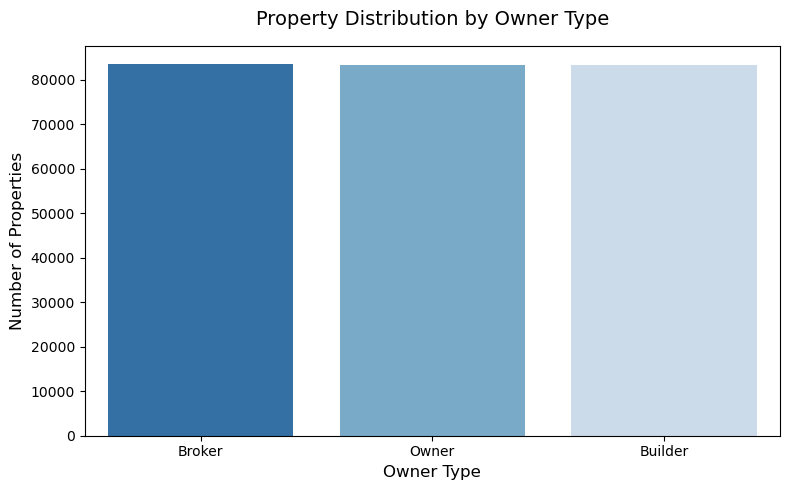

In [64]:
#  Visualize the distribution using a Bar Plot
plt.figure(figsize=(8, 5))
sns.barplot(data=owner_counts, x='Owner_Type', y='Count', palette='Blues_r')
plt.title('Property Distribution by Owner Type', fontsize=14, pad=15)
plt.xlabel('Owner Type', fontsize=12)
plt.ylabel('Number of Properties', fontsize=12)
plt.tight_layout()
plt.show()

##### properties available under each availability status

In [65]:
#  Calculate the count and percentage of properties by Availability status
Availability_Counts = df['Availability_Status'].value_counts().reset_index()
Availability_Counts.columns = ['Availability_Status', 'Count']

Availability_Counts['Percentage'] = (Availability_Counts['Count'] /Availability_Counts['Count'].sum()) * 100

print(' Property Count by Availability_Status: \n')
print(Availability_Counts)

 Property Count by Availability_Status: 

  Availability_Status   Count  Percentage
0  Under_Construction  125035      50.014
1       Ready_to_Move  124965      49.986


C:\Users\DELL\AppData\Local\Temp\ipykernel_54364\1344537458.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=Availability_Counts, x='Availability_Status', y='Count', palette='Blues_r')


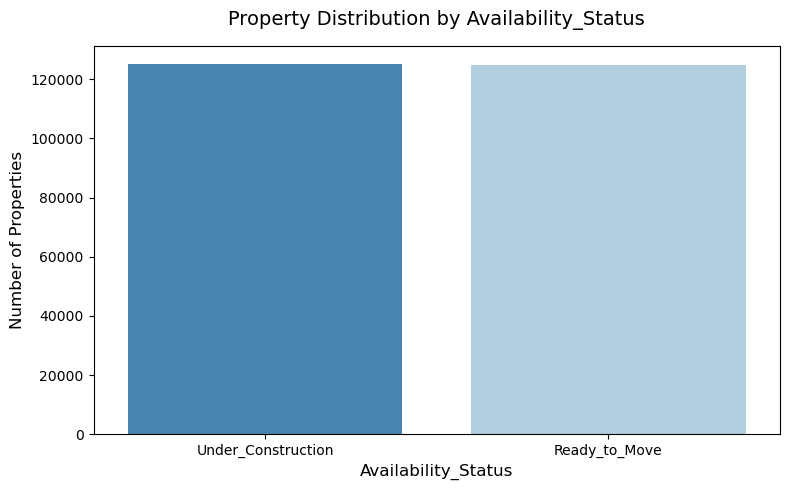

In [66]:
#  Visualize the distribution using a Bar Plot
plt.figure(figsize=(8, 5))
sns.barplot(data=Availability_Counts, x='Availability_Status', y='Count', palette='Blues_r')
plt.title('Property Distribution by Availability_Status', fontsize=14, pad=15)
plt.xlabel('Availability_Status', fontsize=12)
plt.ylabel('Number of Properties', fontsize=12)
plt.tight_layout()
plt.show()

##### parking space affect property price

In [67]:
parking_price = (df.groupby('Parking_Space')['Price_per_SqFt'].agg(['mean', 'median', 'count']).reset_index())
print('Price  by Parking Availability:\n')
print(parking_price)

Price  by Parking Availability:

  Parking_Space      mean  median   count
0            No  0.130725    0.09  125456
1           Yes  0.130467    0.09  124544


C:\Users\DELL\AppData\Local\Temp\ipykernel_54364\1622094664.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,x='Parking_Space',y='Price_per_SqFt',palette='Set2',)


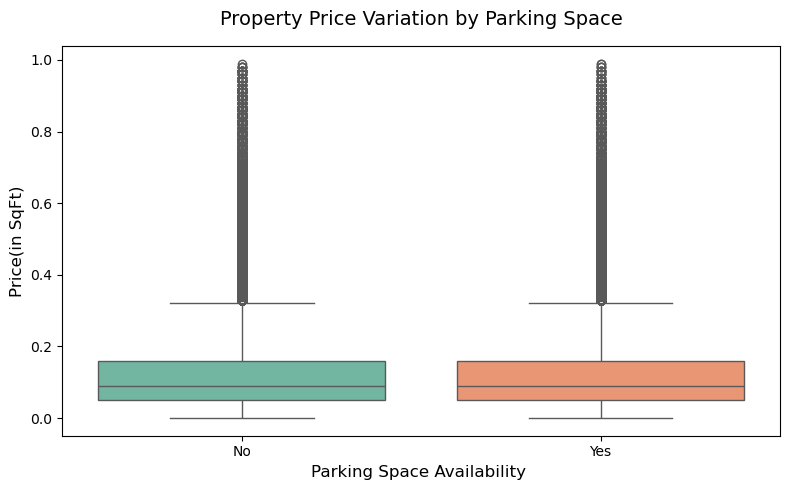

In [68]:
#  Visualize the price distribution using a Box Plot
plt.figure(figsize=(8, 5))
sns.boxplot(data=df,x='Parking_Space',y='Price_per_SqFt',palette='Set2',)
plt.title('Property Price Variation by Parking Space', fontsize=14, pad=15)
plt.xlabel('Parking Space Availability ', fontsize=12)
plt.ylabel('Price(in SqFt)', fontsize=12)
plt.tight_layout()
plt.show()

In [69]:
ameni_ties = (df.groupby('Amenities')['Price_per_SqFt'].agg(['mean', 'median', 'count']).reset_index())
print('Amenities:\n')
print(ameni_ties)

Amenities:

                                    Amenities      mean  median  count
0                                   Clubhouse  0.130319    0.09  10010
1                           Clubhouse, Garden  0.128538    0.09   2497
2                      Clubhouse, Garden, Gym  0.132535    0.09    864
3          Clubhouse, Garden, Gym, Playground  0.124965    0.09    425
4    Clubhouse, Garden, Gym, Playground, Pool  0.130634    0.09    410
..                                        ...       ...     ...    ...
320                     Pool, Playground, Gym  0.131778    0.09    872
321          Pool, Playground, Gym, Clubhouse  0.127980    0.09    401
322  Pool, Playground, Gym, Clubhouse, Garden  0.124880    0.09    416
323             Pool, Playground, Gym, Garden  0.122103    0.09    428
324  Pool, Playground, Gym, Garden, Clubhouse  0.135813    0.09    418

[325 rows x 4 columns]


##### amenities affect price per sq ft

C:\Users\DELL\AppData\Local\Temp\ipykernel_54364\1534784360.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,x='Amenities_Count',y='Price_per_SqFt',palette='Set2',)


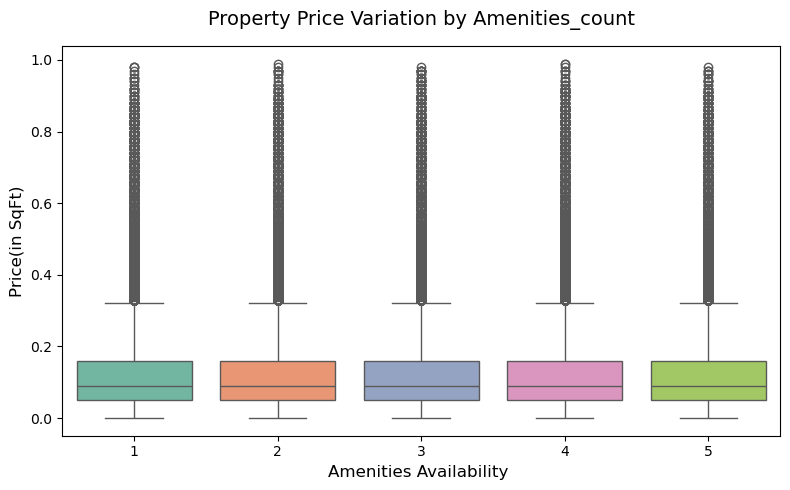

In [70]:
#  Visualize the price distribution using a Box Plot
plt.figure(figsize=(8, 5))
sns.boxplot(data=df,x='Amenities_Count',y='Price_per_SqFt',palette='Set2',)
plt.title('Property Price Variation by Amenities_count', fontsize=14, pad=15)
plt.xlabel('Amenities Availability ', fontsize=12)
plt.ylabel('Price(in SqFt)', fontsize=12)
plt.tight_layout()
plt.show()

#####  display public transport accessibility relate to price per sq ft 

C:\Users\DELL\AppData\Local\Temp\ipykernel_54364\1430451832.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


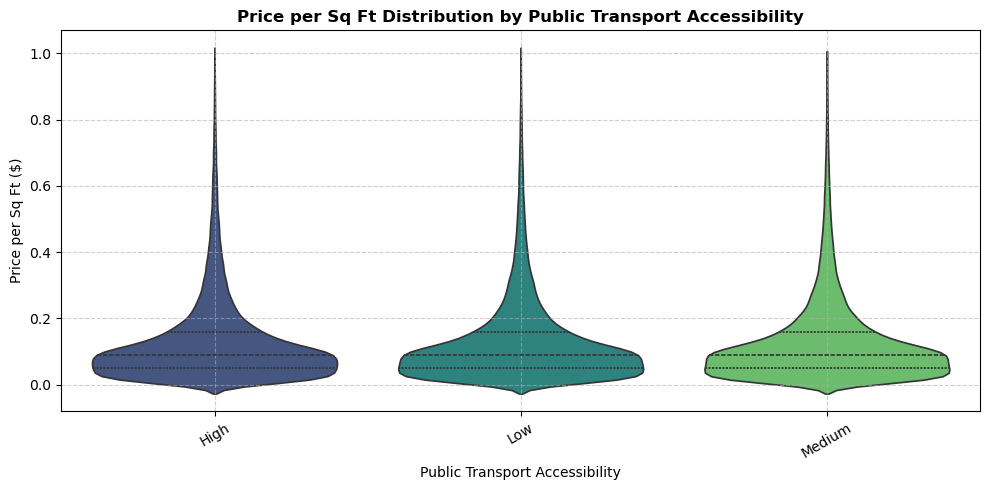

In [71]:
plt.figure(figsize=(10, 5))

sns.violinplot(
    data=df, 
    x='Public_Transport_Accessibility', 
    y='Price_per_SqFt', 
    palette='viridis',
    inner='quartile'  # Shows median and quartiles inside the violin
)

plt.title('Price per Sq Ft Distribution by Public Transport Accessibility', fontsize=12, fontweight='bold')
plt.xlabel('Public Transport Accessibility', fontsize=10)
plt.ylabel('Price per Sq Ft ($)', fontsize=10)
plt.xticks(rotation=30)  # Rotates category labels if they are long
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [73]:
#save cleaned datasets into csv
df.to_csv('cleaned_house_price1.csv',index=False)
print("datasets successfully saved")

datasets successfully saved


In [74]:
df

,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Facing,Owner_Type,Availability_Status,Locality_Encoded,Amenities_Count,Floor_Ratio,Total_Infrastructure_score,Good_Investment,Encode_Property_type,Median_Property_Age
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,West,Owner,Ready_to_Move,483,5,22.000000,13,0,0,19.0
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,North,Builder,Under_Construction,434,5,1.050000,9,1,1,18.0
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,South,Broker,Ready_to_Move,75,4,0.703704,17,1,0,20.0
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,North,Builder,Ready_to_Move,326,5,0.807692,12,0,1,18.0
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,East,Builder,Ready_to_Move,407,5,1.500000,13,1,2,19.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,249996,Gujarat,Ahmedabad,Locality_187,Independent House,5,1995,274.75,0.14,1995,...,East,Broker,Under_Construction,97,5,2.714286,14,0,1,19.0
249996,249997,Tamil Nadu,Chennai,Locality_348,Apartment,1,2293,13.40,0.01,2013,...,South,Broker,Ready_to_Move,276,1,0.600000,18,1,0,17.0
249997,249998,Telangana,Warangal,Locality_225,Villa,4,2910,236.94,0.08,2003,...,South,Builder,Under_Construction,140,1,0.700000,14,1,2,19.0
249998,249999,Odisha,Cuttack,Locality_138,Villa,1,1149,141.66,0.12,2007,...,South,Owner,Ready_to_Move,43,3,1.272727,10,0,2,18.0
